# M4 — Exploratory data analysis

**Project:** NASA Near-Earth Asteroid Hazard Analysis · **Milestone:** M4 (EXPLORE) · **Team:** Burak Avşar · Rana Yalçın · Elif Şahin

**Project question:** *Which asteroid features are linked to the "potentially hazardous" label?*

This notebook reads `data/asteroids.db` **read-only** (built by `python src/load.py` and `python src/clean.py`), writes every figure to `figures/`,
and checks at the end that the database file is byte-for-byte unchanged. Run it with **Restart & Run All**.

| Section | Brief | Explored by |
|---|---|---|
| 0. Parameters | every choice in one place | Burak Avşar |
| 1. Raw versus cleaned | §2.1 | Burak Avşar |
| 2. The question and its summary | §2.2 | Burak Avşar |
| 3. Shape | §2.3 | Burak Avşar |
| 4. Coverage, denominators and the flag filter | §2.4 | Kişi 2 |
| 5. Time | §2.5 | Kişi 2 |
| 6. Relationships | §2.6 | Kişi 3 |
| 7. One comparison, with an interval | §2.7 | Kişi 3 |
| 8. Findings | §2.8 | Burak Avşar (collects) · everyone adds rows |
| 9. Decisions and database check | | Burak Avşar |

**Team rule for this file:** one person edits it at a time (pull → add your section → Restart & Run All → push → tell the group).

## 0. Parameters — every choice in one place

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from explore import DB_PATH, bootstrap_ci, connect_ro, db_fingerprint, ecdf, finish, load_query, query, style

# ---- units
LD_KM = 384_400                 # one lunar distance (mean Earth-Moon distance), the natural unit for close passes
AU_KM = 149_597_870.7           # one astronomical unit (IAU 2012)
PHA_MOID_LD = 0.05 * AU_KM / LD_KM  # NASA's hazard limit 0.05 AU = 19.5 LD, used as a reference line

# ---- flag filter for the key number (named in every query and caption)
#      ok + unusual_*: unusual_low values are the closest real passes, the events this question is about
KEY_FILTER = {"include_unusual": 1, "include_predicted": 1, "exclude_label_mismatch": 0}
KEY_FILTER_TEXT = "flag filter: identity ok, label present, miss distance ok + unusual_*, past + predicted approaches"

# ---- section 3 (shape)
BIN_WIDTHS_LD = (1, 5, 10)      # histogram bin widths tried, in lunar distances
CHOSEN_BIN_LD = 5               # the one reported (justified in section 3)
CLOSE_PASS_LD = 1               # 'closer than the Moon': threshold for the alternative summary

# ---- sections 4-7 (Kişi 2 and Kişi 3 set these)
MIN_EARTH_APPROACHES = 1        # coverage rule placeholder (section 4 justifies the real value)
SEED = 42                       # random seed for every bootstrap
N_BOOT = 2000                   # bootstrap resamples

style()
DB_FINGERPRINT_BEFORE = db_fingerprint()
con = connect_ro()
print("database:", Path(DB_PATH).relative_to(ROOT), "| sha256", DB_FINGERPRINT_BEFORE[:16], "| opened read-only")

database: data/asteroids.db | sha256 9b780ebdc73c3f3e | opened read-only


## 1. Raw versus cleaned: the key number

**Key number:** the **median closest Earth approach** of hazardous and of non-hazardous asteroids, in lunar distances (LD).
For each asteroid we take its closest listed pass to Earth in NASA's 1900–2200 window, then take the median over the asteroids of each group.
It is computed twice: on the M2 tables as loaded, and on the cleaned layer with the flag filter we actually use.

In [2]:
raw_sql = load_query("closest_earth_raw")
clean_sql = load_query("closest_earth_clean")
print(raw_sql)
print(clean_sql)

-- Question: how close does each asteroid come to Earth, by hazard label? (raw M2 tables, as loaded)
-- Grain: one row per asteroid that has at least one Earth approach.
-- Flag filter: none (M2 tables have no flags); every asteroid row counts, including duplicate NASA ids.
SELECT
    a.asteroid_key,
    a.is_potentially_hazardous AS hazardous,
    MIN(p.miss_distance_km)    AS closest_km,
    COUNT(*)                   AS n_earth_approaches
FROM asteroids AS a
JOIN approaches AS p ON p.asteroid_key = a.asteroid_key
WHERE p.orbiting_body = 'Earth'
GROUP BY a.asteroid_key, a.is_potentially_hazardous;

-- Question: how close does each asteroid come to Earth, by hazard label? (cleaned layer)
-- Grain: one row per resolved asteroid that has at least one Earth approach.
-- Flag filter (parameters):
--   identity_flag = 'ok'                     duplicate NASA ids counted once (their approaches are the same events)
--   is_potentially_hazardous IS NOT NULL     label present (label_rule_mismat

In [3]:
raw = query(con, raw_sql)
clean = query(con, clean_sql, KEY_FILTER)
for d in (raw, clean):
    d["closest_ld"] = d["closest_km"] / LD_KM

def key_number(d):
    return d.groupby("hazardous")["closest_ld"].agg(n="size", median="median").round(2)

both = pd.concat({"raw (M2 tables)": key_number(raw), "cleaned (KEY_FILTER)": key_number(clean)}, axis=1)
both.index = both.index.map({0: "not hazardous", 1: "hazardous"})
both

raw (M2 tables)        cleaned (KEY_FILTER)       
                            n median                    n median
hazardous                                                       
not hazardous            3127  40.22                 3127  40.22
hazardous                1030  13.08                 1027  13.07

In [4]:
# What exactly differs between the two inputs?
only_raw = set(raw.asteroid_key) - set(clean.asteroid_key)
dup = query(con, "SELECT asteroid_key, identity_flag FROM asteroid_clean WHERE identity_flag <> 'ok'")
print("asteroids in raw but not in cleaned:", len(only_raw), "| of which duplicate NASA ids:", len(only_raw & set(dup.asteroid_key)))
print("cleaned asteroids whose closest value differs from raw:",
      int((raw.set_index("asteroid_key").closest_km.reindex(clean.asteroid_key).values != clean.closest_km.values).sum()))

asteroids in raw but not in cleaned: 3 | of which duplicate NASA ids: 3
cleaned asteroids whose closest value differs from raw: 0


**Raw vs cleaned.** Cleaning changes the inputs but not the answer. The cleaned version drops the **3 duplicate NASA ids** (section 5 of the M3 report);
their approaches are the same events as those of the numbered asteroid, so the raw table counts three hazardous asteroids twice (n 1,030 → 1,027).
No asteroid's closest distance changes, because the cleaned layer found no invalid miss distance and the flag filter keeps the `unusual_*` values.
So the hazardous median moves by 0.01 LD (13.08 → 13.07) and the non-hazardous one not at all — a result, not a non-event: our cleaning was about
coverage and identity, not bad numbers, and this key number is robust to it.

## 2. The question and its summary

**Question (one sentence):** *How much closer to Earth do potentially hazardous asteroids typically come than non-hazardous ones?*

**Summary: the median** of each asteroid's closest approach. Why the median: the question asks about the *typical* asteroid; closest distances are right-skewed
(section 3), so the mean is pulled up by a long tail of distant passes; and each asteroid counts once, whatever its number of approaches.

**Alternative summaries of the same variable:** the mean; the 10th percentile (the close tail); and the **share of asteroids that ever pass closer than the Moon (1 LD)**.
Do they rank the groups the same way?

In [5]:
def summaries(d):
    g = d.groupby("hazardous")["closest_ld"]
    out = pd.DataFrame({
        "n": g.size(),
        "median_LD": g.median(),
        "mean_LD": g.mean(),
        "p10_LD": g.quantile(0.10),
        "share_closer_than_moon_%": g.apply(lambda s: 100 * (s < CLOSE_PASS_LD).mean()),
        "n_closer_than_moon": g.apply(lambda s: int((s < CLOSE_PASS_LD).sum())),
        "share_within_0.05AU_%": g.apply(lambda s: 100 * (s <= PHA_MOID_LD).mean()),
    }).round(2)
    out.index = out.index.map({0: "not hazardous", 1: "hazardous"})
    return out

S = summaries(clean)
S

,n,median_LD,mean_LD,p10_LD,share_closer_than_moon_%,n_closer_than_moon,share_within_0.05AU_%
hazardous,,,,,,,
not hazardous,3127,40.22,46.74,6.28,1.28,40,25.26
hazardous,1027,13.07,16.16,4.28,1.17,12,74.59


In [6]:
# Is the 'closer than the Moon' tie made of different asteroids? Size (H) of the asteroids that pass inside 1 LD
h = query(con, "SELECT asteroid_key, absolute_magnitude_h FROM asteroid_clean")
close = clean[clean.closest_ld < CLOSE_PASS_LD].merge(h, on="asteroid_key")
close.groupby("hazardous")["absolute_magnitude_h"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
hazardous,,,,,,,,
0,40.0,26.92,2.29,17.81,26.18,26.85,28.67,30.10
1,12.0,20.25,1.26,18.28,19.25,20.45,21.20,21.91


**Finding — the summary decides the ranking.** By the **median** (and the mean and the 10th percentile), hazardous asteroids come about **three times closer**
to Earth than non-hazardous ones. By the **share that ever passes closer than the Moon**, the two groups are **level** (about 1.2–1.3% each).
The two rankings answer different questions: the median asks *how close does a typical asteroid of the group come*; the share asks *how often does
a really close pass happen*. The asteroids that pass inside 1 LD without the label are **small**: 39 of the 40 have H > 22 (diameter below ~140 m),
so they fail the size half of NASA's definition however close they come. The label is about *size and orbit*, not about the closest pass on record.

## 3. Shape

The key variable is shown in two ways that do not share the same weakness: **histograms** (with the bin width chosen after trying three) and an **ECDF**
on a log scale (no bins at all, and it shows the close tail that a linear histogram squeezes into one bar).

figures/m4_fig1_hist_bin_widths.png


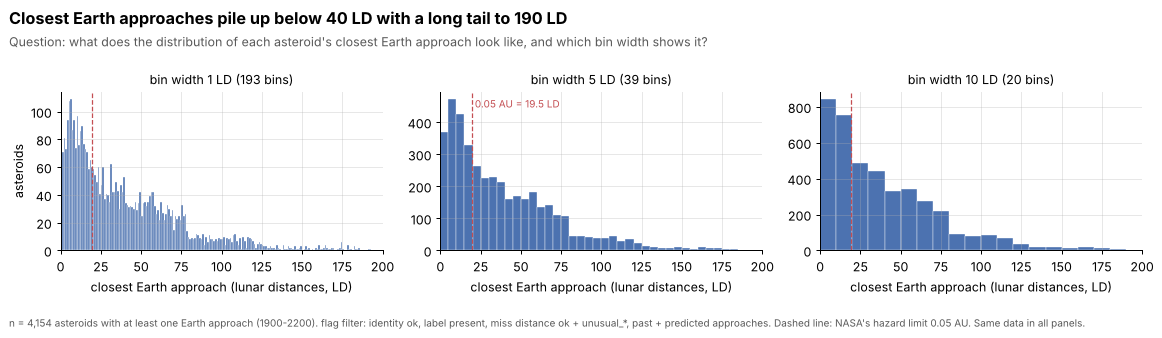

In [7]:
# Three bin widths, same data, same axes
x = clean["closest_ld"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, w in zip(axes, BIN_WIDTHS_LD):
    bins = np.arange(0, x.max() + w, w)
    ax.hist(x, bins=bins, color="#4C72B0", edgecolor="white", linewidth=0.3)
    ax.axvline(PHA_MOID_LD, color="#C44E52", ls="--", lw=1)
    ax.set_title(f"bin width {w} LD ({len(bins) - 1} bins)", fontsize=10, fontweight="normal")
    ax.set_xlabel("closest Earth approach (lunar distances, LD)")
    ax.set_xlim(0, 200)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("asteroids")
axes[1].text(PHA_MOID_LD + 2, axes[1].get_ylim()[1] * 0.9, "0.05 AU = 19.5 LD", color="#C44E52", fontsize=8)
path = finish(fig, "m4_fig1_hist_bin_widths",
              "Closest Earth approaches pile up below 40 LD with a long tail to 190 LD",
              "Question: what does the distribution of each asteroid's closest Earth approach look like, and which bin width shows it?",
              f"n = {len(x):,} asteroids with at least one Earth approach (1900-2200). {KEY_FILTER_TEXT}. "
              "Dashed line: NASA's hazard limit 0.05 AU. Same data in all panels.")
plt.show()
print(path.relative_to(ROOT))

**Bin width.** At **1 LD** (193 bins) the bars are noisy: the tail bins hold a handful of asteroids each and the eye follows the noise.
At **10 LD** the first bin swallows the rise from 0 to the peak at 5–10 LD. **5 LD** is the coarsest width that keeps the three features every panel hints at:
the peak at 5–10 LD, the drop just after **19.5 LD** (NASA's 0.05 AU limit) and a **step at ~78 LD**. It is the width used for the group comparison.

figures/m4_fig2_closest_by_group.png


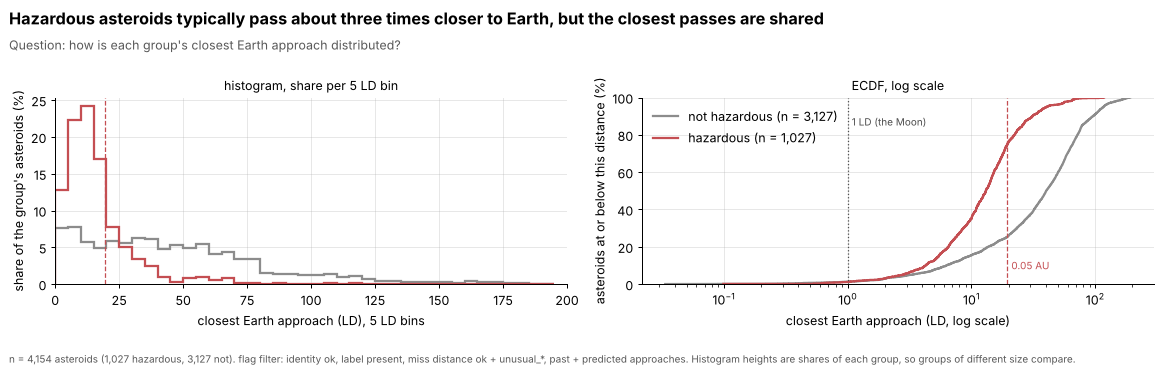

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = {0: "#8C8C8C", 1: "#C44E52"}
names = {0: "not hazardous", 1: "hazardous"}
bins = np.arange(0, clean.closest_ld.max() + CHOSEN_BIN_LD, CHOSEN_BIN_LD)
for hz in (0, 1):
    s = clean.loc[clean.hazardous == hz, "closest_ld"]
    axes[0].hist(s, bins=bins, weights=np.full(len(s), 100 / len(s)), histtype="step", lw=1.8,
                 color=colors[hz], label=f"{names[hz]} (n = {len(s):,})")
    xs, ys = ecdf(s)
    axes[1].step(xs, ys * 100, where="post", color=colors[hz], lw=1.8, label=f"{names[hz]} (n = {len(s):,})")
for ax in axes:
    ax.axvline(PHA_MOID_LD, color="#C44E52", ls="--", lw=1)
axes[1].axvline(CLOSE_PASS_LD, color="0.3", ls=":", lw=1)
axes[1].text(CLOSE_PASS_LD * 1.08, 85, "1 LD (the Moon)", fontsize=8, color="0.3")
axes[1].text(PHA_MOID_LD * 1.08, 8, "0.05 AU", fontsize=8, color="#C44E52")
axes[0].set(xlabel="closest Earth approach (LD), 5 LD bins", ylabel="share of the group's asteroids (%)", xlim=(0, 200))
axes[0].set_ylim(bottom=0)
axes[0].set_title("histogram, share per 5 LD bin", fontsize=10, fontweight="normal")
axes[1].set(xscale="log", xlabel="closest Earth approach (LD, log scale)", ylabel="asteroids at or below this distance (%)", ylim=(0, 100))
axes[1].set_title("ECDF, log scale", fontsize=10, fontweight="normal")
axes[1].legend(loc="upper left")
path = finish(fig, "m4_fig2_closest_by_group",
              "Hazardous asteroids typically pass about three times closer to Earth, but the closest passes are shared",
              "Question: how is each group's closest Earth approach distributed?",
              f"n = {len(clean):,} asteroids ({(clean.hazardous == 1).sum():,} hazardous, {(clean.hazardous == 0).sum():,} not). "
              f"{KEY_FILTER_TEXT}. Histogram heights are shares of each group, so groups of different size compare.")
plt.show()
print(path.relative_to(ROOT))

In [9]:
# Where does the hazardous distribution stop? share above the 0.05 AU line, and the shape numbers quoted below
for hz in (0, 1):
    s = clean.loc[clean.hazardous == hz, "closest_ld"]
    print(f"{names[hz]:<14} n={len(s):>5,}  skew={s.skew():5.2f}  median={s.median():6.2f}  mean={s.mean():6.2f}  "
          f"above 0.05 AU: {100 * (s > PHA_MOID_LD).mean():5.1f}%  max={s.max():6.1f} LD")

not hazardous  n=3,127  skew= 1.12  median= 40.22  mean= 46.74  above 0.05 AU:  74.7%  max= 193.0 LD
hazardous      n=1,027  skew= 2.60  median= 13.07  mean= 16.16  above 0.05 AU:  25.4%  max= 118.5 LD


**The step at ~78 LD (0.2 AU).** A cliff in a histogram is often a limit, not nature. For each asteroid we look at its *farthest* listed Earth approach:
if NASA lists every approach up to a fixed distance, the farthest one sits just below that distance.

In [10]:
far = query(con, '''
    SELECT c.asteroid_key, c.is_potentially_hazardous AS hazardous, MAX(p.miss_distance_km) AS farthest_km
    FROM asteroid_clean AS c JOIN approach_clean AS p ON p.asteroid_key = c.asteroid_key
    WHERE p.orbiting_body = 'Earth' AND c.identity_flag = 'ok' AND p.miss_distance_km IS NOT NULL
    GROUP BY c.asteroid_key, c.is_potentially_hazardous''')  # flag filter: identity ok, miss distance not NULL, all timings
far["farthest_au"] = far.farthest_km / AU_KM
print(pd.cut(far.farthest_au, [0, 0.05, 0.1, 0.15, 0.2005, 0.3, 0.4, 0.5005]).value_counts().sort_index().to_string())

clean2 = clean.merge(far[["asteroid_key", "farthest_au"]], on="asteroid_key")
clean2["listing_limit"] = np.where(clean2.farthest_au <= 0.2005, "listed to 0.2 AU", "listed to 0.5 AU")
t = clean2.groupby(["listing_limit", "hazardous"])["closest_ld"].agg(n="size", median_LD="median").round(2).unstack()
t.columns = [f"{a} ({'hazardous' if b else 'not hazardous'})" for a, b in t.columns]
t

farthest_au
(0.0, 0.05]     237
(0.05, 0.1]     112
(0.1, 0.15]     129
(0.15, 0.2]    1594
(0.2, 0.3]       65
(0.3, 0.4]      179
(0.4, 0.5]     1838


,n (not hazardous),n (hazardous),median_LD (not hazardous),median_LD (hazardous)
listing_limit,,,,
listed to 0.2 AU,1418,654,38.48,12.86
listed to 0.5 AU,1709,373,44.65,13.69


The farthest listed passes **pile up just below 0.2 AU (1,594 asteroids) and just below 0.5 AU (1,838)**, with few in between: NASA lists Earth approaches
up to one of two cut-offs. The table splits asteroids by whether their farthest pass is within 0.2 AU (2,072) or beyond (2,082); the first group also holds
some asteroids with only a few, close passes, so the split is approximate. For asteroids listed to 0.2 AU, a closest approach beyond 0.2 AU (78 LD) cannot appear at all — that is the step. Cause **unknown** (NASA does not
document it; numbered asteroids are more often in the 0.2 AU group). It does **not** change the key comparison: within each listing limit the hazardous
median is about a third of the non-hazardous one.

**Shape.** Both groups are **right-skewed**, with no second mode. The **hazardous** group is packed below the 0.05 AU line (19.5 LD): about three
quarters of hazardous asteroids pass within it, and the histogram falls steeply just after it — partly by construction, because the label requires an orbit
that *can* come within 0.05 AU (MOID). The quarter above the line are asteroids whose listed passes in 1900–2200 never came as close as their orbits allow.
The **non-hazardous** group is flat and wide, out to ~190 LD. On the log-scale ECDF the two curves are far apart in the middle but **meet below 1 LD** —
the same tie as the share in section 2. **Consequence for section 2:** with this much skew the mean overstates the typical distance in both groups
(mean > median), so the median is the right summary; and any single summary hides that the closest passes are not a hazardous-only phenomenon.

## 4. Coverage, denominators and the flag filter  *(Kişi 2)*

> TODO (Kişi 2): coverage table (approaches per asteroid and per period, against how many there could be); a coverage rule for every aggregate
> (set `MIN_EARTH_APPROACHES` in section 0 and justify it), one result **with and without** the rule; the key number with **two flag filters**
> (e.g. `KEY_FILTER` vs `{"include_unusual": 0, ...}` or `exclude_label_mismatch = 1`) and which one we report. Notes from section 3: the closest approach of an asteroid with 1
> listed Earth approach and of one with 400 are not the same measurement (463 non-hazardous and 34 hazardous asteroids have a single one; medians 12 vs 21);
> and NASA lists Earth approaches to two different cut-offs, 0.2 AU and 0.5 AU (section 3) — a denominator to state.

## 5. Time  *(Kişi 2)*

> TODO (Kişi 2): the clock (all NASA times are UTC; say why UTC fits); the edges (the 1900 and 2200 ends of NASA's window, the one 1899-12-31 row, the
> 2200s decade that holds only ~450 approaches); patterns at two scales (e.g. decade and year, past vs predicted via `timing_flag`); the calendar
> check replaced by a justified alternative (no human calendar in orbital mechanics).

## 6. Relationships  *(Kişi 3)*

> TODO (Kişi 3): one relationship that matters for the question — plot first (scatter or binned medians), then Pearson and Spearman; remove the few
> extreme points and recompute; compare within orbit class. Do **not** use H, MOID or diameter as features (they define the label).

## 7. One comparison, with an interval  *(Kişi 3)*

> TODO (Kişi 3): the difference between hazardous and non-hazardous with a 95% bootstrap interval — the unit is the **asteroid** (one value each, as in `clean`),
> not the approach; `bootstrap_ci(a, b, n_boot=N_BOOT, seed=SEED)` is in `src/explore.py`. Composition check: do the two groups have the same mix of
> orbit classes and coverage? Compare within orbit class (Simpson). Say how many comparisons were looked at.

## 8. Findings

| ID | Finding (one sentence) | Evidence | Label | What would change it | Explored by |
|---|---|---|---|---|---|
| F-01 | Hazardous asteroids' median closest Earth approach is about three times closer than non-hazardous ones' (13.1 vs 40.2 LD; n = 1,027 vs 3,127). | §2 table; `figures/m4_fig2_closest_by_group.png` | Exploratory — and partly **by construction** (the label requires MOID ≤ 0.05 AU) | Comparing at equal coverage (number of listed approaches), or within orbit class | Burak Avşar |
| F-02 | The share of asteroids that ever pass closer than the Moon is the same in both groups (~1.2–1.3%); those close passers without the label are small (H > 22). | §2 tables; ECDF in fig 2 | Exploratory | A size-matched comparison (same H range); more close passes (only 52 asteroids: 40 + 12) | Burak Avşar |
| F-03 | Cleaning barely changes the key number: only the 3 duplicate NASA ids drop out (hazardous median 13.08 → 13.07 LD) and no closest distance changes. | §1 queries and table | Confirmed (arithmetic: 0 invalid miss distances, 3 identity duplicates) | A new retrieval with invalid miss distances or more duplicate ids | Burak Avşar |
| F-04 | Closest approach is right-skewed in both groups; three quarters of hazardous asteroids pass within 0.05 AU and their histogram drops right after it. | `figures/m4_fig1_hist_bin_widths.png`, fig 2, §3 skew numbers | Exploratory (drop at 0.05 AU partly by construction) | Using MOID-free features only; a different time window | Burak Avşar |
| F-05 | NASA lists Earth approaches to two cut-offs (farthest passes pile up below 0.2 AU for 1,594 asteroids and below 0.5 AU for 1,838), which creates a step at ~78 LD; the hazardous / non-hazardous gap holds within each. | §3 farthest-approach table | Exploratory; cause unknown | NASA documentation of the listing rule; a retrieval where the cut-off is requested explicitly | Burak Avşar |
| F-06… | *(Kişi 2: coverage, flag filter, time)* | | | | Kişi 2 |
| F-…  | *(Kişi 3: relationship, comparison)* | | | | Kişi 3 |

### Back to cleaning
* **Missed by the cleaned layer:** the listing cut-off of each asteroid's Earth approaches (0.2 or 0.5 AU, F-05). It is coverage information an analysis
  needs; to be added to the M3 issues register (I-13, inferred) and, if the team agrees, as a column in `asteroid_clean`. Nothing the layer got *wrong*:
  the key number is unchanged by cleaning (F-03). *(Kişi 2 and 3: add yours.)*

### Forward to modelling
* **Leakage:** H, MOID and diameter define the label; the closest Earth approach is bounded below by MOID, so it partly leaks the label too (F-01, F-04).
  M7 should treat it with care, or use it only as a check, not as a feature.
* **Size matters for the label but not for closeness:** the closest passes include many small, non-hazardous asteroids (F-02); a model must not learn
  "close pass ⇒ hazardous".
* **Unequal coverage:** an asteroid's closest approach depends on how many approaches NASA lists for it (1 to 473); M7 needs a per-asteroid coverage feature or rule (section 4).

## 9. Decisions and database check

In [11]:
con.close()
print("parameters used:")
for k in ["LD_KM", "AU_KM", "PHA_MOID_LD", "KEY_FILTER", "BIN_WIDTHS_LD", "CHOSEN_BIN_LD", "CLOSE_PASS_LD",
          "MIN_EARTH_APPROACHES", "SEED", "N_BOOT"]:
    print(f"  {k} = {globals()[k]!r}")
print("figures written:", sorted(p.name for p in (ROOT / "figures").glob("m4_*.png")))
after = db_fingerprint()
print("database unchanged:", after == DB_FINGERPRINT_BEFORE)
assert after == DB_FINGERPRINT_BEFORE, "the notebook changed the database"


parameters used:
  LD_KM = 384400
  AU_KM = 149597870.7
  PHA_MOID_LD = 19.458620018210198
  KEY_FILTER = {'include_unusual': 1, 'include_predicted': 1, 'exclude_label_mismatch': 0}
  BIN_WIDTHS_LD = (1, 5, 10)
  CHOSEN_BIN_LD = 5
  CLOSE_PASS_LD = 1
  MIN_EARTH_APPROACHES = 1
  SEED = 42
  N_BOOT = 2000
figures written: ['m4_fig1_hist_bin_widths.png', 'm4_fig2_closest_by_group.png']
database unchanged: True
